# Model 1 — Logistic Regression

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import FeatureUnion, make_pipeline as sk_make_pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, GroupKFold, cross_validate
from sklearn.metrics import (make_scorer, fbeta_score, recall_score, precision_score, f1_score, accuracy_score,
                             balanced_accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve)
from sklearn.metrics import get_scorer
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

from imblearn.pipeline import Pipeline          # imblearn Pipeline: resampling happens only on training folds
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42

## 1. Load the train/test split and define the feature sets


In [2]:
train = pd.read_csv("../results/outputs/processed_dataset_train.csv")
test  = pd.read_csv("../results/outputs/processed_dataset_test.csv")
print("train:", train.shape, " test:", test.shape)

TARGET = "next_risk_class"
NON_FEATURES = ["patient_id", "timestamp", "date", "time", "code", "code_description",
                "risk_class",           # current band - circular with glucose_mg_dl
                "next_glucose",         # the next reading itself - would leak the answer
                "daily_total_insulin",  # whole-day total - includes insulin given AFTER this reading
                "reading_index",        # position in the patient's record - not physiology (see Section 8/10 evidence)
                TARGET]

PIPELINE_PCS = [c for c in train.columns if c.startswith("PC")]   # computed with the leaky column - not used
FEATURES = [c for c in train.columns if c not in NON_FEATURES and c not in PIPELINE_PCS]
print(f"{len(FEATURES)} clean input features (pipeline PC columns excluded: {len(PIPELINE_PCS)})")
print(FEATURES)

y_train, y_test = train[TARGET], test[TARGET]
groups_train = train["patient_id"]

print("\nClass distribution (train):")
print(y_train.value_counts(normalize=True).round(3))

train: (10635, 49)  test: (2659, 49)
21 clean input features (pipeline PC columns excluded: 17)
['hour', 'is_weekend', 'glucose_mg_dl', 'prev_glucose', 'hours_since_prev', 'rolling_mean_3', 'rolling_std_3', 'insulin_regular_6h', 'insulin_nph_6h', 'insulin_ultralente_6h', 'meals_6h', 'exercise_6h', 'hypo_symptoms_6h', 'dow_sin', 'dow_cos', 'ctx_post_meal', 'ctx_pre_breakfast', 'ctx_pre_lunch', 'ctx_pre_snack', 'ctx_pre_supper', 'ctx_unspecified']

Class distribution (train):
next_risk_class
Normal           0.523
Hyperglycemic    0.361
Hypoglycemic     0.116
Name: proportion, dtype: float64


In [3]:
# Evidence for dropping daily_total_insulin: it has ONE value per patient per day, even on days with several
# readings - so a morning reading already "knows" the evening's doses.
per_day = train.groupby(["patient_id", "date"])["daily_total_insulin"].nunique()
readings = train.groupby(["patient_id", "date"]).size()
print("patient-days with a single daily_total_insulin value:", f"{(per_day == 1).mean():.1%}")
print("...of which have more than one reading that day     :", f"{(readings[per_day == 1] > 1).mean():.1%}")

patient-days with a single daily_total_insulin value: 100.0%
...of which have more than one reading that day     : 89.4%


## 2. Why Logistic Regression suits this problem

In [4]:
# Scale check: the two mostly-zero insulin columns are on a much larger scale than everything else
train[FEATURES].agg(["min", "max", "std"]).T.sort_values("max", ascending=False).head(6).round(2)

,min,max,std
insulin_ultralente_6h,0.00,30.00,6.05
insulin_nph_6h,0.00,13.33,3.09
hours_since_prev,-1.20,8.28,0.96
insulin_regular_6h,-0.60,5.40,0.64
rolling_std_3,-0.88,3.29,0.69
rolling_mean_3,-1.69,3.26,0.71


## 3. Evaluation metrics

In [5]:
HYPO = "Hypoglycemic"

# Small wrappers score only the Hypoglycemic class. (Passing labels=... straight into make_scorer
# fails on string class names, because the scorer defaults to pos_label=1.)
def hypo_recall(y_true, y_pred):
    return recall_score(y_true, y_pred, labels=[HYPO], average="macro", zero_division=0)
def hypo_precision(y_true, y_pred):
    return precision_score(y_true, y_pred, labels=[HYPO], average="macro", zero_division=0)
def hypo_f2(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=2, labels=[HYPO], average="macro", zero_division=0)

scoring = {
    "balanced_acc":   "balanced_accuracy",
    "hypo_f2":        make_scorer(hypo_f2),
    "hypo_recall":    make_scorer(hypo_recall),
    "hypo_precision": make_scorer(hypo_precision),
    "macro_f1":       "f1_macro",
    "accuracy":       "accuracy",
    "roc_auc_ovr":    "roc_auc_ovr",   # macro one-vs-rest ROC AUC from predicted probabilities
}

def test_metrics(y_true, y_pred):
    return {
        "balanced_acc":   balanced_accuracy_score(y_true, y_pred),
        "hypo_recall":    hypo_recall(y_true, y_pred),
        "hypo_precision": hypo_precision(y_true, y_pred),
        "hypo_f2":        hypo_f2(y_true, y_pred),
        "accuracy":       accuracy_score(y_true, y_pred),
        "macro_f1":       f1_score(y_true, y_pred, average="macro"),
    }

**Why not tune on hypo F2 or hypo recall?** Two trivial "models" show the problem. Predicting *every* reading as
Hypoglycemic gets hypo-recall 1.0 and a high hypo-F2, while balanced accuracy gives both trivial models exactly
0.333. Section 5 compares this trivial hypo-F2 against every trained model.

In [6]:
trivial = pd.DataFrame([
    {"model": "always Hypoglycemic", **test_metrics(y_train, np.full(len(y_train), HYPO))},
    {"model": "always Normal",       **test_metrics(y_train, np.full(len(y_train), "Normal"))},
]).round(3)
TRIVIAL_HYPO_F2 = trivial.loc[0, "hypo_f2"]
trivial

,model,balanced_acc,hypo_recall,hypo_precision,hypo_f2,accuracy,macro_f1
0,always Hypoglycemic,0.333,1.0,0.116,0.396,0.116,0.069
1,always Normal,0.333,0.0,0.000,0.000,0.523,0.229


## 4. Hyperparameter tuning — GridSearchCV

In [7]:
# StandardScaler -> PCA(95% variance). imblearn does not allow a Pipeline as an intermediate step,
# so the block is wrapped in a FeatureUnion (which imblearn accepts).
def pca_block():
    return sk_make_pipeline(StandardScaler(), PCA(n_components=0.95, random_state=RANDOM_STATE))

FEATURE_OPTIONS = {
    "original": "passthrough",
    "pca":      FeatureUnion([("pcs", pca_block())]),
    "all":      FeatureUnion([("original", "passthrough"), ("pcs", pca_block())]),
}

pipe = Pipeline([
    ("features", "passthrough"),
    ("scaler",  "passthrough"),
    ("sampler", "passthrough"),
    ("clf",     LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
])

C_VALUES = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1, 10]
common = {"features": list(FEATURE_OPTIONS.values()),
          "scaler": ["passthrough", StandardScaler()], "clf__C": C_VALUES}
param_grid = [
    {**common, "sampler": ["passthrough"], "clf__class_weight": [None, "balanced"]},
    {**common, "sampler": [SMOTE(random_state=RANDOM_STATE), RandomUnderSampler(random_state=RANDOM_STATE)],
     "clf__class_weight": [None]},
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

gs = GridSearchCV(pipe, param_grid, scoring=scoring, refit="balanced_acc", cv=cv, n_jobs=-1,
                  return_train_score=True,   # training-fold scores, for the overfitting check
                  error_score="raise")       # fail loudly instead of silently returning NaN
gs.fit(train[FEATURES], y_train)

def feature_set_name(step):
    if isinstance(step, str): return "original"
    return "all" if len(step.transformer_list) == 2 else "pca"

cv_all = pd.DataFrame(gs.cv_results_)
cv_all["feature_set"] = cv_all["param_features"].apply(feature_set_name)
print(cv_all.groupby("feature_set")["mean_test_balanced_acc"].max().round(3).rename("best CV balanced acc"))
print("\nTotal configurations evaluated:", len(cv_all))

feature_set
all         0.477
original    0.477
pca         0.480
Name: best CV balanced acc, dtype: float64

Total configurations evaluated: 192


## 5. Comparison across varieties (cross-validation, training set)
Each row below is one **variety** = feature set × scaler × imbalance strategy, shown with its best `C`.

In [8]:
def strategy(sampler, class_weight):
    if isinstance(sampler, SMOTE): return "SMOTE"
    if isinstance(sampler, RandomUnderSampler): return "Undersampling"
    return "Class weights" if class_weight == "balanced" else "None"

cv_all["imbalance"] = [strategy(s, w) for s, w in zip(cv_all["param_sampler"], cv_all["param_clf__class_weight"])]
cv_all["scaling"] = cv_all["param_scaler"].apply(lambda s: "none" if isinstance(s, str) else "StandardScaler")
cv_all["C"] = cv_all["param_clf__C"].astype(float)

metric_cols = ["mean_test_balanced_acc", "std_test_balanced_acc", "mean_test_hypo_f2", "mean_test_hypo_recall",
               "mean_test_hypo_precision", "mean_test_macro_f1", "mean_test_accuracy", "mean_test_roc_auc_ovr"]
best_per_variety = (cv_all.sort_values("mean_test_balanced_acc", ascending=False)
                          .groupby(["feature_set", "scaling", "imbalance"], as_index=False).first())
varieties = (best_per_variety[["feature_set", "scaling", "imbalance", "C"] + metric_cols]
             .rename(columns=lambda c: c.replace("mean_test_", ""))
             .sort_values("balanced_acc", ascending=False).reset_index(drop=True))
print(f"{len(varieties)} varieties (each tuned over {len(C_VALUES)} values of C)")
varieties.assign(C=varieties["C"].map(lambda c: f"{c:g}")).round(3)

24 varieties (each tuned over 8 values of C)


,feature_set,scaling,imbalance,C,balanced_acc,std_test_balanced_acc,hypo_f2,hypo_recall,hypo_precision,macro_f1,accuracy,roc_auc_ovr
0,pca,StandardScaler,Class weights,1e-06,0.480,0.011,0.379,0.519,0.183,0.434,0.462,0.648
1,pca,StandardScaler,SMOTE,1e-05,0.480,0.012,0.368,0.488,0.185,0.438,0.470,0.647
2,pca,none,SMOTE,0.001,0.479,0.014,0.365,0.477,0.188,0.441,0.475,0.650
3,all,StandardScaler,SMOTE,0.001,0.477,0.011,0.361,0.467,0.189,0.441,0.477,0.653
4,original,none,SMOTE,0.001,0.477,0.007,0.354,0.456,0.187,0.442,0.479,0.652
5,original,StandardScaler,SMOTE,0.0001,0.476,0.006,0.354,0.458,0.185,0.438,0.473,0.651
6,pca,none,Class weights,0.01,0.476,0.013,0.359,0.467,0.187,0.441,0.477,0.650
7,all,none,Class weights,0.0001,0.475,0.011,0.358,0.461,0.189,0.439,0.474,0.648
8,original,none,Class weights,0.001,0.474,0.009,0.347,0.441,0.187,0.443,0.482,0.652
9,all,none,SMOTE,0.0001,0.473,0.008,0.354,0.457,0.186,0.437,0.472,0.649


In [9]:
# Effect of each choice, averaged over the other settings (best C per variety)
# (feature set and scaling are compared only over varieties that handle imbalance - the "None" rows
#  never predict Hypoglycemic, so they would just drag every average down equally)
cols_show = ["balanced_acc", "hypo_recall", "hypo_precision", "hypo_f2", "macro_f1", "accuracy"]
handled = varieties[varieties.imbalance != "None"]
print(varieties.groupby("imbalance")[cols_show].mean().round(3).sort_values("balanced_acc", ascending=False), "\n")
for factor in ["feature_set", "scaling"]:
    print(handled.groupby(factor)[cols_show].mean().round(3).sort_values("balanced_acc", ascending=False), "\n")

print(f"Trivial 'always Hypoglycemic' hypo-F2 : {TRIVIAL_HYPO_F2:.3f}")
print(f"Best hypo-F2 of any trained model     : {cv_all['mean_test_hypo_f2'].max():.3f}")
print("-> tuning on hypo-F2 would have rewarded the trivial model over every real one"
      if TRIVIAL_HYPO_F2 > cv_all['mean_test_hypo_f2'].max() else
      "-> here the best trained model edges past the trivial one, but only just")

               balanced_acc  hypo_recall  hypo_precision  hypo_f2  macro_f1  \
imbalance                                                                     
SMOTE                 0.477        0.467           0.187    0.359     0.440   
Class weights         0.475        0.464           0.186    0.357     0.440   
Undersampling         0.471        0.450           0.186    0.350     0.439   
None                  0.402        0.000           0.000    0.000     0.376   

               accuracy  
imbalance                
SMOTE             0.474  
Class weights     0.476  
Undersampling     0.477  
None              0.568   

             balanced_acc  hypo_recall  hypo_precision  hypo_f2  macro_f1  \
feature_set                                                                 
pca                 0.477        0.479           0.186    0.364     0.438   
all                 0.473        0.454           0.187    0.353     0.439   
original            0.473        0.448           0.186    0

In [10]:
N_FOLDS = cv.get_n_splits()
cv_all["se_bal"] = cv_all["std_test_balanced_acc"] / np.sqrt(N_FOLDS)
top = cv_all.loc[cv_all["mean_test_balanced_acc"].idxmax()]
threshold = top["mean_test_balanced_acc"] - top["se_bal"]

IMB_RANK   = {"Class weights": 0, "Undersampling": 1, "SMOTE": 2, "None": 3}
FS_RANK    = {"original": 0, "pca": 1, "all": 2}
SCALE_RANK = {"StandardScaler": 0, "none": 1}

tied = cv_all[cv_all["mean_test_balanced_acc"] >= threshold].copy()
tied["rank"] = list(zip(tied.imbalance.map(IMB_RANK), tied.feature_set.map(FS_RANK),
                        tied.scaling.map(SCALE_RANK), -tied.mean_test_balanced_acc))
chosen = tied.sort_values("rank").iloc[0]

print(f"Highest CV balanced acc : {top.mean_test_balanced_acc:.4f}  "
      f"({top.feature_set}, {top.scaling}, {top.imbalance}, C={top.C:g})")
print(f"One-SE threshold        : {threshold:.4f}   -> {len(tied)} configurations within one standard error of the best")
print(f"Chosen (first by preference)  : {chosen.mean_test_balanced_acc:.4f} ± {chosen.std_test_balanced_acc:.4f}  "
      f"({chosen.feature_set}, {chosen.scaling}, {chosen.imbalance}, C={chosen.C:g})")

tied[["feature_set", "scaling", "imbalance", "C", "mean_test_balanced_acc", "std_test_balanced_acc"]] \
    .sort_values("mean_test_balanced_acc", ascending=False).head(10).round(4)

Highest CV balanced acc : 0.4804  (pca, StandardScaler, Class weights, C=1e-06)
One-SE threshold        : 0.4755   -> 23 configurations within one standard error of the best
Chosen (first by preference)  : 0.4804 ± 0.0110  (pca, StandardScaler, Class weights, C=1e-06)


,feature_set,scaling,imbalance,C,mean_test_balanced_acc,std_test_balanced_acc
9,pca,StandardScaler,Class weights,0.0000,0.4804,0.0110
113,pca,StandardScaler,SMOTE,0.0000,0.4803,0.0117
101,pca,StandardScaler,SMOTE,0.0000,0.4799,0.0107
125,pca,StandardScaler,SMOTE,0.0001,0.4791,0.0116
21,pca,StandardScaler,Class weights,0.0000,0.4786,0.0109
136,pca,none,SMOTE,0.0010,0.4786,0.0142
33,pca,StandardScaler,Class weights,0.0001,0.4785,0.0135
185,pca,StandardScaler,SMOTE,10.0000,0.4777,0.0128
161,pca,StandardScaler,SMOTE,0.1000,0.4777,0.0128
173,pca,StandardScaler,SMOTE,1.0000,0.4777,0.0128


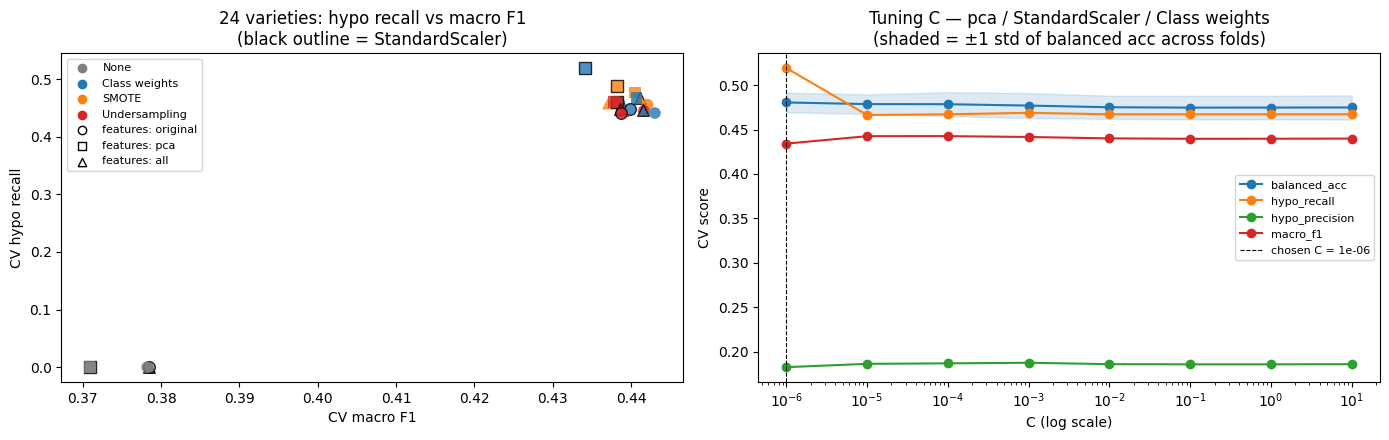

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# (a) hypo-recall vs macro-F1 for every variety - the trade-off the imbalance strategies create
markers = {"original": "o", "pca": "s", "all": "^"}
colors = {"None": "tab:gray", "Class weights": "tab:blue", "SMOTE": "tab:orange", "Undersampling": "tab:red"}
for _, r in varieties.iterrows():
    axes[0].scatter(r.macro_f1, r.hypo_recall, marker=markers[r.feature_set], color=colors[r.imbalance],
                    s=70, alpha=0.8, edgecolor="black" if r.scaling == "StandardScaler" else "none")
for k, c in colors.items():
    axes[0].scatter([], [], color=c, label=k)
for k, m in markers.items():
    axes[0].scatter([], [], marker=m, color="white", edgecolor="black", label=f"features: {k}")
axes[0].set_xlabel("CV macro F1"); axes[0].set_ylabel("CV hypo recall")
axes[0].set_title(f"{len(varieties)} varieties: hypo recall vs macro F1\n(black outline = StandardScaler)")
axes[0].legend(fontsize=8, loc="best")

# (b) tuning curve for C within the chosen variety
curve = cv_all[(cv_all.feature_set == chosen.feature_set) & (cv_all.scaling == chosen.scaling) &
               (cv_all.imbalance == chosen.imbalance)].sort_values("C")
for m in ["balanced_acc", "hypo_recall", "hypo_precision", "macro_f1"]:
    axes[1].plot(curve.C, curve[f"mean_test_{m}"], marker="o", label=m)
axes[1].fill_between(curve.C, curve.mean_test_balanced_acc - curve.std_test_balanced_acc,
                     curve.mean_test_balanced_acc + curve.std_test_balanced_acc, alpha=0.15, color="tab:blue")
axes[1].axvline(chosen.C, color="black", ls="--", lw=0.8, label=f"chosen C = {chosen.C:g}")
axes[1].set_xscale("log"); axes[1].set_xlabel("C (log scale)"); axes[1].set_ylabel("CV score")
axes[1].set_title(f"Tuning C — {chosen.feature_set} / {chosen.scaling} / {chosen.imbalance}\n"
                  "(shaded = ±1 std of balanced acc across folds)")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Final model — refit on the full training set, evaluated once on the test set
The chosen configuration is rebuilt from its parameters, refit on all training rows, and evaluated on the test set.

Final model: pca features | StandardScaler | Class weights | C = 1e-06

               precision    recall  f1-score   support

Hyperglycemic      0.511     0.479     0.495       960
 Hypoglycemic      0.182     0.519     0.270       308
       Normal      0.688     0.436     0.534      1391

     accuracy                          0.461      2659
    macro avg      0.461     0.478     0.433      2659
 weighted avg      0.566     0.461     0.489      2659



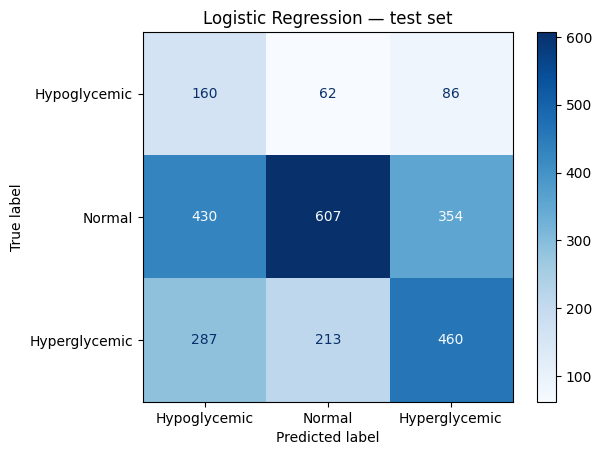

In [12]:
chosen_params = cv_all.loc[chosen.name, "params"]
final_model = clone(pipe).set_params(**chosen_params).fit(train[FEATURES], y_train)
print("Final model:", chosen.feature_set, "features |", chosen.scaling, "|", chosen.imbalance, "| C =", f"{chosen.C:g}")

y_pred = final_model.predict(test[FEATURES])
print("\n" + classification_report(y_test, y_pred, digits=3))

LABELS = ["Hypoglycemic", "Normal", "Hyperglycemic"]
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=LABELS), display_labels=LABELS).plot(cmap="Blues")
plt.title("Logistic Regression — test set"); plt.show()

### ROC AUC — ranking quality, independent of the threshold
Precision and recall above depend on the default rule "highest probability wins". ROC AUC instead asks how well the
model's probabilities rank readings: if the hypo probability ranks real hypo readings above the rest, a different
threshold could trade precision for recall. Each curve is one class against the other two.

Test ROC AUC - Hypoglycemic vs rest : 0.646
Test ROC AUC - macro one-vs-rest    : 0.652


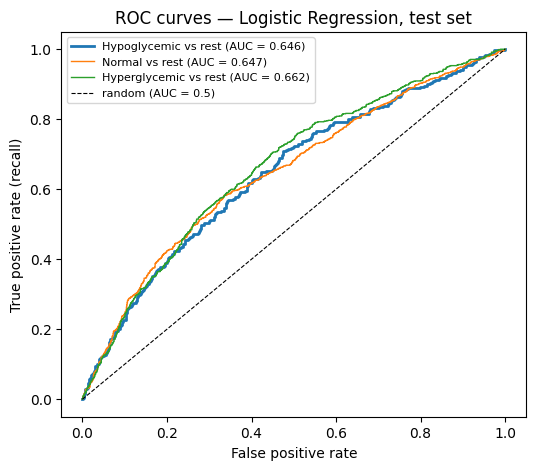

In [15]:
proba = final_model.predict_proba(test[FEATURES])
classes = list(final_model.named_steps["clf"].classes_)
hypo_auc  = roc_auc_score((y_test == HYPO).astype(int), proba[:, classes.index(HYPO)])
macro_auc = roc_auc_score(y_test, proba, multi_class="ovr", average="macro", labels=classes)
print(f"Test ROC AUC - Hypoglycemic vs rest : {hypo_auc:.3f}")
print(f"Test ROC AUC - macro one-vs-rest    : {macro_auc:.3f}")

plt.figure(figsize=(6, 5))
for c in LABELS:
    fpr, tpr, _ = roc_curve((y_test == c).astype(int), proba[:, classes.index(c)])
    auc_c = roc_auc_score((y_test == c).astype(int), proba[:, classes.index(c)])
    plt.plot(fpr, tpr, label=f"{c} vs rest (AUC = {auc_c:.3f})", lw=2 if c == HYPO else 1)
plt.plot([0, 1], [0, 1], "k--", lw=0.8, label="random (AUC = 0.5)")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curves — Logistic Regression, test set"); plt.legend(fontsize=8); plt.show()

### Overfitting check — training vs cross-validation vs test


In [16]:
fit_rows = {"balanced_acc": "balanced_acc", "hypo_recall": "hypo_recall",
            "macro_f1": "macro_f1", "roc_auc_ovr": "roc_auc_ovr"}
test_scores = {**test_metrics(y_test, y_pred), "roc_auc_ovr": macro_auc}
overfit = pd.DataFrame({
    "Train (in-fold)":  {m: chosen[f"mean_train_{m}"] for m in fit_rows},
    "CV (validation)":  {m: chosen[f"mean_test_{m}"] for m in fit_rows},
    "Test":             {m: test_scores[m] for m in fit_rows},
})
overfit["train - CV gap"] = overfit["Train (in-fold)"] - overfit["CV (validation)"]
display(overfit.round(3))

# Does the gap grow as regularisation weakens (larger C)?
gap_curve = curve.assign(gap=curve.mean_train_balanced_acc - curve.mean_test_balanced_acc)
print("Train - CV balanced-accuracy gap across C (chosen variety):")
print(gap_curve.set_index(gap_curve.C.map(lambda c: f"{c:g}"))["gap"].round(4).to_string())

,Train (in-fold),CV (validation),Test,train - CV gap
balanced_acc,0.482,0.480,0.478,0.002
hypo_recall,0.522,0.519,0.519,0.002
macro_f1,0.436,0.434,0.433,0.002
roc_auc_ovr,0.654,0.648,0.652,0.005


Train - CV balanced-accuracy gap across C (chosen variety):
C
1e-06     0.0018
1e-05     0.0031
0.0001    0.0039
0.001     0.0043
0.01      0.0059
0.1       0.0060
1         0.0060
10        0.0059


## 9. Conclusion, limitations and improvements
### Conclusion
The selected configuration was **PCA features + StandardScaler + class weights, C = 1e-6**. On the test set it reached balanced accuracy **0.478**, hypo recall **0.519**, hypo precision **0.182** and hypo-vs-rest ROC AUC **0.646**. This is a clear improvement over the untuned default (balanced accuracy 0.397, no hypo events identified at the default decision rule).

There is little evidence of overfitting: balanced accuracy was 0.482 (train), 0.480 (CV) and 0.478 (test). Time-ordered validation gave balanced accuracy 0.499 and hypo recall 0.532; unseen-patient GroupKFold gave 0.460 and 0.498. Logistic Regression is therefore a useful linear baseline, though its overall discrimination is modest.

### Limitations
- Linear decision boundaries cannot capture non-linear interactions between glucose, insulin, time and context.
- The chosen model uses PCA, so coefficients describe components rather than original clinical variables (less interpretable).
- Hypo precision is low (0.182): higher sensitivity comes with a large false-alarm burden.
- Unseen-patient performance is slightly lower than row-wise/time-ordered performance.

### Possible improvements
- Try non-linear models (Random Forest, gradient boosting, MLP) and compare under the same protocol.
- Calibrate probabilities and choose the hypo decision threshold on a dedicated temporal validation set.
- Keep an original-feature Logistic Regression as an interpretable baseline.
- Evaluate on additional patients and independent temporal data.